# L17 — Camera Models and Calibration — Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L17-CameraModels/L17_Camera_Models.ipynb)

This notebook accompanies **Lecture 17**. Every earlier lecture worked with pixels. Today we connect pixels to
the **3-D world**: where does a point in front of the camera land in the photo?

1. **The pinhole camera and K**: similar triangles, focal length in pixels, the image centre, and the 3 × 3
   matrix K that holds them.
2. **Where the camera is (R and t)**: world vs camera coordinates, ground pixel size from a drone and from a
   1958 air photo, and why a tilted camera over flat ground gives a **homography** (L8).
3. **Lens distortion and calibration**: bent lines, the radial model, and Zhang's checkerboard method, first on
   rendered photos where we know the answer, then on real photos. Then the payoff: drawing a 3-D cube on the board.

No downloads beyond `L17.zip` (0.8 MB). Everything runs on a CPU in under a minute.

| Section | Topic |
|---------|-------|
| 0 | Setup and data |
| 1 | The pinhole camera by hand |
| 2 | Focal length in pixels, field of view, and K |
| 3 | What changes K: zoom, crop, resize |
| 4 | Where the camera is: R and t; ground pixel size |
| 5 | A tilted camera over flat ground is a homography |
| 6 | Lens distortion: the radial model by hand |
| 7 | Zhang's method on rendered photos (we know the answer) |
| 8 | Calibrating a real camera |
| 9 | Pose: drawing a 3-D cube on the board |
| 10 | The 1958 air camera |
| 11 | Try at home: calibrate your phone |

In [2]:
import os, time, glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY, BLUE = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                                    "#1A3A5C", "#7B4EA0", "#7A8FA6", "#4A7BD0")
np.set_printoptions(suppress=True, precision=3)
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.5.3


## 0 · Setup and data

`L17.zip` (0.8 MB) holds

* `calib/left01.jpg … left14.jpg`: 13 photos of a printed checkerboard (9 × 6 inner corners) taken with one
  640 × 480 camera. They are OpenCV's own sample calibration photos (`opencv/samples/data`; there is no
  `left10`).
* `frame_16046-19.jpg`: the 1958 air photo from AL5 and L8, resized to 1000 pixels tall.

Safe to re-run.

In [3]:
import io, urllib.request, zipfile

BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch_zip(name, needed):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present"); return
    with urllib.request.urlopen(BASE + name, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(".")
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded and extracted")

fetch_zip("L17.zip", ["L17/calib/left01.jpg", "L17/calib/left14.jpg", "L17/frame_16046-19.jpg"])
FILES = sorted(glob.glob("L17/calib/left*.jpg"))
frame58 = cv2.imread("L17/frame_16046-19.jpg", cv2.IMREAD_GRAYSCALE)
print(len(FILES), "checkerboard photos,", cv2.imread(FILES[0]).shape[1::-1], "| 1958 frame", frame58.shape[::-1])

L17.zip: already present
13 checkerboard photos, (640, 480) | 1958 frame (953, 1000)


## 1 · The pinhole camera by hand

A pinhole camera is a dark box with a tiny hole. Light from a point in the scene goes through the hole in a
straight line and lands on the back wall, upside down. Every camera since (film, phone, drone) follows the same
geometry, with a lens in place of the hole.

Similar triangles give the whole model. A point at height $Y$ and distance $Z$ in front of the hole lands at

$$ y = f\,\frac{Y}{Z} $$

on a wall a distance $f$ behind the hole (the **focal length**). Twice as far away → half as big.

**Example 1: a solar-eclipse viewer.** The sun is 0.53° across (0.0093 radians). In a box 1 m long, its image is
$1000\ \text{mm} \times 0.0093 = 9.3$ mm across. A longer box gives a bigger (and dimmer) sun.

**Example 2: a person in a photo.** A 1.8 m person, 10 m away, with $f = 1500$ pixels: $1500 \times 1.8 / 10 = 270$ px tall.

In [4]:
sun = np.radians(0.53)                       # the sun's angular size
for box_mm in [1000, 2000]:
    print(f"pinhole box {box_mm/1000:.0f} m long -> sun image {box_mm * sun:.1f} mm across")

f = 1500                                     # focal length in pixels
for Z in [10, 20, 30]:
    print(f"1.8 m person at {Z:2d} m -> {f * 1.8 / Z:.0f} px tall")

pinhole box 1 m long -> sun image 9.3 mm across
pinhole box 2 m long -> sun image 18.5 mm across
1.8 m person at 10 m -> 270 px tall
1.8 m person at 20 m -> 135 px tall
1.8 m person at 30 m -> 90 px tall


**Same size, different look.** Zooming in (a bigger $f$) and stepping back (a bigger $Z$) can keep the person
the same size in the photo, because only $f/Z$ matters for things at one distance. But the *background* (much
further away) and the *depth* of the face change: that is why portrait photos are taken on the 2× or 3× lens.
Here a wire-frame house is drawn twice, the same height in the photo, from 6 m (wide lens) and from 18 m
(3× zoom).

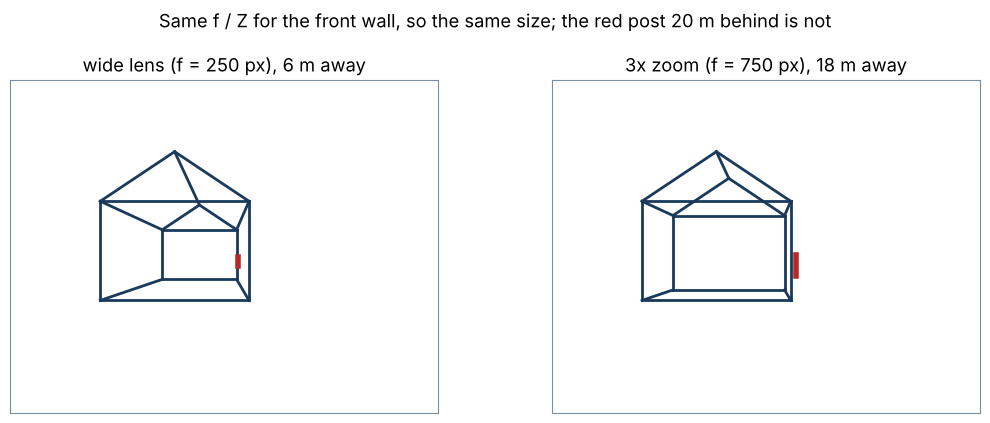

front wall, wide: 167 px | zoom: 167 px
post 20 m behind, wide: 16 px | zoom: 29 px


In [5]:
# A simple house: 6 m wide, 6 m deep, 4 m walls, ridge at 6 m; plus a 2 m post 20 m behind its front wall.
box = np.array([[x, y, z] for x in (-3, 3) for y in (0, 4) for z in (0, 6)], float)
ridge = np.array([[0, 6, 0], [0, 6, 6]], float)
EDGES = [(0,1),(2,3),(4,5),(6,7),(0,2),(1,3),(4,6),(5,7),(0,4),(1,5),(2,6),(3,7)]
post = np.array([[5, 0, 26], [5, 2, 26]], float)          # 20 m behind the front of the house

def view(f, Z0, ax, title):
    def proj(P):                                            # camera at (2, 1.7, -Z0) looking along +z
        X, Y, Z = P[:, 0] - 2.0, P[:, 1] - 1.7, P[:, 2] + Z0
        return f * X / Z, f * Y / Z                         # (plotted with y up)
    u, v = proj(box)
    for a, b in EDGES: ax.plot([u[a], u[b]], [v[a], v[b]], color=NAVY, lw=2)
    ru, rv = proj(ridge); ax.plot(ru, rv, color=NAVY, lw=2)
    for a, b in [(2, 0), (3, 1)]:                           # roof lines (front and back gable)
        ax.plot([u[a], ru[b]], [v[a], rv[b]], color=NAVY, lw=2); ax.plot([u[a+4], ru[b]], [v[a+4], rv[b]], color=NAVY, lw=2)
    pu, pv = proj(post); ax.plot(pu, pv, color=RED, lw=4)
    ax.set_xlim(-360, 360); ax.set_ylim(-260, 300); ax.set_aspect("equal")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(GREY)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
view(250, 6, ax[0], "wide lens (f = 250 px), 6 m away")
view(750, 18, ax[1], "3x zoom (f = 750 px), 18 m away")
plt.suptitle("Same f / Z for the front wall, so the same size; the red post 20 m behind is not", y=1.0)
plt.tight_layout(); plt.show()
print("front wall, wide:", round(250 * 4 / 6), "px | zoom:", round(750 * 4 / 18), "px")
print("post 20 m behind, wide:", round(250 * 2 / 32), "px | zoom:", round(750 * 2 / 52), "px")

## 2 · Focal length in pixels, field of view, and K

Lens makers quote $f$ in millimetres; images are measured in pixels. Divide by the size of one sensor pixel:

$$ f_\text{px} = \frac{f_\text{mm}}{\text{pixel size in mm}} $$

A phone lens with $f = 5$ mm and 2 µm pixels has $f = 5 / 0.002 = 2500$ px. The 1958 air camera (§10) had a lens
of about 152 mm, and the scan has about 0.076 mm per pixel, so $f \approx 2000$ px in the full scan.

**Field of view.** The edge of an image $W$ pixels wide is $W/2$ pixels from the centre, so

$$ \tan\frac{\theta}{2} = \frac{W/2}{f}. $$

With $f = W/2$ the view is 90° wide; $f = W$ gives 53°; $f = 3W$ gives 19°. That is roughly a phone's 0.5×, 1×
and 3× buttons: three focal lengths.

In [6]:
W = 4000                                         # a phone photo 4000 px wide
for name, fpx in [("0.5x", W / 2), ("1x", W), ("3x", 3 * W)]:
    fov = 2 * np.degrees(np.arctan((W / 2) / fpx))
    print(f"{name:>4}: f = {fpx:5.0f} px -> horizontal field of view {fov:4.1f} deg")

0.5x: f =  2000 px -> horizontal field of view 90.0 deg
  1x: f =  4000 px -> horizontal field of view 53.1 deg
  3x: f = 12000 px -> horizontal field of view 18.9 deg


**The image centre.** The pixel the lens looks straight at, $(c_x, c_y)$, is usually close to (not exactly at)
the middle of the photo. Pixel coordinates start at the top-left corner, so

$$ u = f\,\frac{X}{Z} + c_x, \qquad v = f\,\frac{Y}{Z} + c_y . $$

(Camera axes: $x$ right, $y$ **down**, $z$ forward, the way OpenCV does it.)

**K: the same thing as a matrix.** With homogeneous coordinates (L8: add a 1, divide by the last number at the end):

$$ \begin{bmatrix} u\,Z \\ v\,Z \\ Z \end{bmatrix} =
   \underbrace{\begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix}}_{K}
   \begin{bmatrix} X \\ Y \\ Z \end{bmatrix} $$

$f_x$ and $f_y$ are equal for square pixels. **K is the camera's "insides"** (the *intrinsics*): it does not
change when you carry the camera around.

In [7]:
K = np.array([[500., 0, 320],
              [0, 500., 240],
              [0, 0, 1]])

def project(K, Xc):
    # 3-D points in camera coordinates (N x 3) -> pixels (N x 2)
    h = (K @ np.asarray(Xc, float).T).T           # [uZ, vZ, Z]
    return h[:, :2] / h[:, 2:]                     # divide by the last number

for P in [(1, 0.5, 5), (-2, 1, 10), (0, 0, 7)]:
    print(f"point {P} m -> K X = {K @ np.array(P, float)} -> pixel {project(K, [P])[0]}")

point (1, 0.5, 5) m -> K X = [2100. 1450.    5.] -> pixel [420. 290.]
point (-2, 1, 10) m -> K X = [2200. 2900.   10.] -> pixel [220. 290.]
point (0, 0, 7) m -> K X = [2240. 1680.    7.] -> pixel [320. 240.]


The last line is a point straight ahead: it lands on $(c_x, c_y)$ whatever its distance.

## 3 · What changes K: zoom, crop, resize

You will change K yourself all the time without noticing:

* **zoom** (or switch lens): $f$ changes;
* **crop** the photo: $(c_x, c_y)$ moves by the crop offset, $f$ does not change;
* **resize** by a factor $s$: $f$, $c_x$ and $c_y$ all scale by $s$.

Check it: project a point, then crop and resize the "photo" and see where the same point lands.

In [8]:
P = [(1.0, 0.5, 5.0)]
u0 = project(K, P)[0]

crop_x, crop_y = 100, 40                          # cut 100 px off the left, 40 off the top
Kc = K.copy(); Kc[0, 2] -= crop_x; Kc[1, 2] -= crop_y
s = 0.5                                           # then resize to half size
Ks = Kc.copy(); Ks[:2] *= s

print("original pixel     ", u0)
print("after the crop     ", project(Kc, P)[0], "= original - (100, 40)")
print("after crop + resize", project(Ks, P)[0], "= (original - (100, 40)) x 0.5")
print("K after crop + resize:\n", Ks)

original pixel      [420. 290.]
after the crop      [320. 250.] = original - (100, 40)
after crop + resize [160. 125.] = (original - (100, 40)) x 0.5
K after crop + resize:
 [[250.   0. 110.]
 [  0. 250. 100.]
 [  0.   0.   1.]]


**For projects:** if you resize tiles to 512 px for a network or cut a crop out of a scanned frame, any
measurement that uses K (ground pixel size, heights from stereo, flattening an oblique) must use the
cropped and resized K.

## 4 · Where the camera is: R and t; ground pixel size

K works in **camera coordinates** (metres in front of the lens). Points in the world (a map, the floor, a
checkerboard) have their own coordinates. Moving between the two is a rotation and a shift:

$$ X_\text{cam} = R\,X_\text{world} + t $$

$R$ (3 × 3) turns the world to line up with the camera; $t$ (3 numbers) moves it. Together they are the
camera's **pose** (the *extrinsics*): 3 numbers for the turn, 3 for the position. Then K does the rest:

$$ \text{pixel} \sim K\,[\,R \mid t\,]\,X_\text{world} \qquad (P = K[R \mid t] \text{ is 3 × 4}). $$

**Example: a drone looking straight down from 100 m.** World axes: $x$ east, $y$ north, $z$ up. The camera's
$x$ is east, its $y$ (image down) is south, its $z$ (forward) is down:
$R = \text{diag}(1, -1, -1)$, and the camera sits at $C = (0, 0, 100)$, so $t = -R\,C = (0, 0, 100)$.

In [9]:
def pose_from(R, C):
    # rotation R and camera centre C (world coordinates) -> t = -R C
    return -R @ np.asarray(C, float)

Kd = np.array([[1000., 0, 500], [0, 1000., 500], [0, 0, 1]])       # 1000 x 1000 px drone camera
R_down = np.diag([1., -1, -1])
t_down = pose_from(R_down, (0, 0, 100))
print("t =", t_down)

def world_to_pixel(K, R, t, Xw):
    Xc = (R @ np.asarray(Xw, float).T).T + t
    return project(K, Xc), Xc

for Xw in [(10, 20, 0), (-30, 0, 0)]:
    px, Xc = world_to_pixel(Kd, R_down, t_down, [Xw])
    print(f"ground point {Xw} -> camera {Xc[0]} -> pixel {px[0]}")

t = [  0.   0. 100.]
ground point (10, 20, 0) -> camera [ 10. -20. 100.] -> pixel [600. 300.]
ground point (-30, 0, 0) -> camera [-30.   0. 100.] -> pixel [200. 500.]


**Ground pixel size (GSD).** Looking straight down from height $H$, one pixel covers $H / f$ metres of ground
(similar triangles again). The drone: $100 / 1000 = 0.1$ m per pixel. The 1958 frames cover about 1.2 m per pixel
in the full scan, and $f \approx 2000$ px (§2), so the plane was about $1.2 \times 2000 = 2400$ m up (see §10 for
the assumptions). This is the same $f$ (in pixels) as L11's $Z = fB/d$.

In [10]:
for H in [100, 50]:
    print(f"drone at {H} m, f = 1000 px -> {H / 1000 * 100:.0f} cm per pixel")
print(f"1958: 1.2 m/px x f 2000 px -> flying height about {1.2 * 2000:.0f} m")

drone at 100 m, f = 1000 px -> 10 cm per pixel
drone at 50 m, f = 1000 px -> 5 cm per pixel
1958: 1.2 m/px x f 2000 px -> flying height about 2400 m


## 5 · A tilted camera over flat ground is a homography

Tilt the camera forward and the ground in the photo becomes a trapezoid: near things big, far things small.
That is an **oblique** photo (the Sharpe collection).

For points on flat ground, $Z_\text{world} = 0$, so the third column of $R$ is multiplied by zero and drops out:

$$ K\,[\,r_1\ r_2\ r_3\ t\,] \begin{bmatrix} X \\ Y \\ 0 \\ 1 \end{bmatrix}
   = \underbrace{K\,[\,r_1\ r_2\ t\,]}_{3 \times 3\ =\ H} \begin{bmatrix} X \\ Y \\ 1 \end{bmatrix}. $$

A 3 × 3 matrix from plane to image: a **homography**, exactly L8's model. That is why L8's homography lined up
two 1958 photos so well: PEI is nearly flat. Here we tilt a camera 0°, 30° and 60° over the 1958 photo
(laid on the ground), always 2000 m from its middle, then **flatten** the 60° view back with $H^{-1}$.

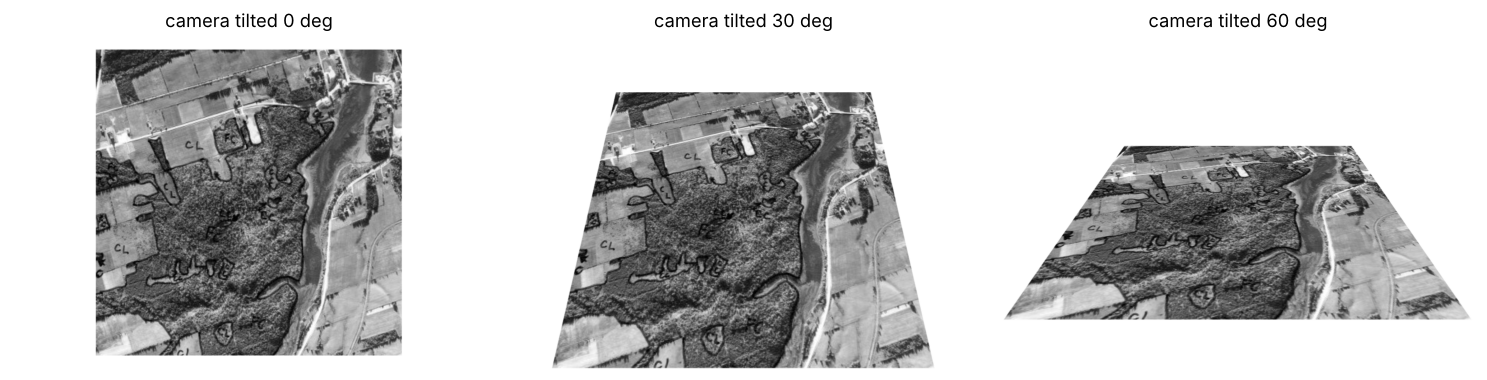

In [11]:
def look_at(C, target=(0, 0, 0)):
    # rotation for a camera at C looking at target, image x = world east (x)
    z = np.asarray(target, float) - np.asarray(C, float); z /= np.linalg.norm(z)
    x = np.array([1., 0, 0]); y = np.cross(z, x)
    return np.vstack([x, y, z])

# Lay a 1600 x 1600 m piece of the 1958 photo on the ground: 4 m per texture pixel, centred on the origin.
tex = frame58[200:600, 300:700]                       # 400 x 400 px
S = 4.0
T_ground_from_tex = np.array([[S, 0, -200 * S], [0, -S, 200 * S], [0, 0, 1]])   # texture px -> ground (X, Y)

Kt = np.array([[800., 0, 500], [0, 800., 350], [0, 0, 1]]); size = (1000, 700)
views, Hs = [], []
for tilt in [0, 30, 60]:
    D = 2000.0                                           # camera 2000 m from the middle of the photo
    C = (0, -D * np.sin(np.radians(tilt)), D * np.cos(np.radians(tilt)))
    R = look_at(C); t = pose_from(R, C)
    H = Kt @ np.column_stack([R[:, 0], R[:, 1], t])      # K [r1 r2 t]
    Hs.append(H)
    views.append(cv2.warpPerspective(tex, H @ T_ground_from_tex, size, borderValue=255))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
for a, im, tilt in zip(ax, views, [0, 30, 60]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(f"camera tilted {tilt} deg"); a.axis("off")
plt.tight_layout(); plt.show()

Check that $K[r_1\ r_2\ t]$ is the same homography OpenCV finds from four ground points and their pixels (L8's
`findHomography`), then use it backwards to flatten the 60° view.

K[r1 r2 t] / its corner:
 [[  0.4     0.217 500.   ]
 [  0.     -0.048 350.   ]
 [  0.      0.      1.   ]]
findHomography from 4 points:
 [[  0.4     0.217 500.   ]
 [  0.     -0.048 350.   ]
 [  0.      0.      1.   ]]
largest difference: 1.4688418673358683e-05


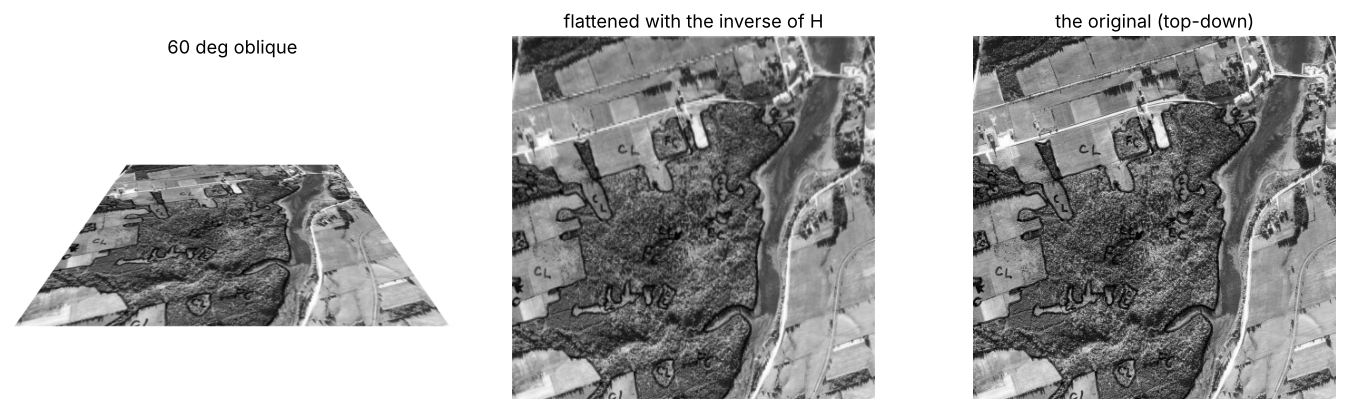

In [12]:
H60 = Hs[2]
ground4 = np.array([[-600, -600], [600, -600], [600, 600], [-600, 600]], float)
pix4 = cv2.perspectiveTransform(ground4.reshape(-1, 1, 2), H60).reshape(-1, 2)
H_cv, _ = cv2.findHomography(ground4, pix4)
print("K[r1 r2 t] / its corner:\n", H60 / H60[2, 2])
print("findHomography from 4 points:\n", H_cv)
print("largest difference:", np.abs(H60 / H60[2, 2] - H_cv).max())

# Flatten: image -> ground -> texture pixels
flat = cv2.warpPerspective(views[2], np.linalg.inv(H60 @ T_ground_from_tex), (400, 400), borderValue=255)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
ax[0].imshow(views[2], cmap="gray", vmin=0, vmax=255); ax[0].set_title("60 deg oblique")
ax[1].imshow(flat, cmap="gray", vmin=0, vmax=255); ax[1].set_title("flattened with the inverse of H")
ax[2].imshow(tex, cmap="gray", vmin=0, vmax=255); ax[2].set_title("the original (top-down)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

The flattened view matches the original, but the far part (top) is blurry: in the oblique it was squeezed into
few pixels, and flattening cannot bring that detail back. Real obliques add two problems this simulation does
not have: we don't know $K$, $R$ or $t$ (so $H$ must be found from matches, L8), and hills and buildings are not
on the flat plane.

## 6 · Lens distortion: the radial model by hand

Real lenses bend straight lines, most near the edges. Wide-angle lenses (GoPro, phone 0.5×, dash cams) bow lines
outward: **barrel** distortion. Some zoom lenses pinch them inward: **pincushion**.

The usual model works in *normalised* coordinates $x = X/Z$, $y = Y/Z$ (before K), with $r^2 = x^2 + y^2$:

$$ x_\text{d} = x\,(1 + k_1 r^2 + k_2 r^4), \qquad y_\text{d} = y\,(1 + k_1 r^2 + k_2 r^4). $$

$k_1 < 0$: barrel (points pulled in, more at the edge). $k_1 > 0$: pincushion. The centre never moves.

**By hand**, $k_1 = -0.3$, $k_2 = 0$, $f = 500$, centre $(320, 240)$:

* a point near the corner, $(x, y) = (0.4, 0.3)$: $r^2 = 0.25$, factor $1 - 0.3 \times 0.25 = 0.925$ →
  $(0.37, 0.2775)$ → pixel $(505, 378.75)$ instead of $(520, 390)$: about 19 px;
* a point near the middle, $(0.2, 0)$: $r^2 = 0.04$, factor $0.988$ → pixel 418.8 instead of 420: about 1 px.

In [13]:
def distort(xy, k1, k2=0.0):
    xy = np.asarray(xy, float); r2 = (xy ** 2).sum(-1, keepdims=True)
    return xy * (1 + k1 * r2 + k2 * r2 ** 2)

def to_pixel(xy, f=500, c=(320, 240)):
    return np.asarray(xy) * f + c

for p in [(0.4, 0.3), (0.2, 0.0)]:
    d = distort([p], -0.3)[0]
    print(f"{p}: factor {d[0]/p[0]:.3f} -> pixel {to_pixel(d)} instead of {to_pixel(p)}, "
          f"moved {np.linalg.norm(to_pixel(d) - to_pixel(p)):.1f} px")

(0.4, 0.3): factor 0.925 -> pixel [505.   378.75] instead of [520. 390.], moved 18.8 px
(0.2, 0.0): factor 0.988 -> pixel [418.8 240. ] instead of [420. 240.], moved 1.2 px


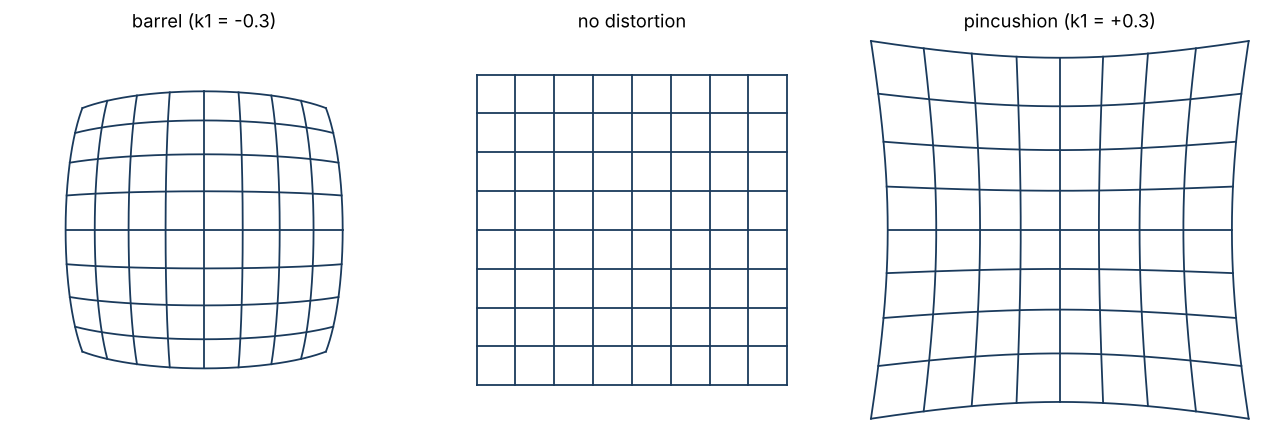

In [14]:
# A straight grid seen through three lenses
g = np.linspace(-0.6, 0.6, 9); fine = np.linspace(-0.6, 0.6, 200)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
for a, k1, title in zip(ax, [-0.3, 0.0, 0.3], ["barrel (k1 = -0.3)", "no distortion", "pincushion (k1 = +0.3)"]):
    for v in g:
        for line in (np.column_stack([fine, np.full_like(fine, v)]), np.column_stack([np.full_like(fine, v), fine])):
            d = distort(line, k1); a.plot(d[:, 0], d[:, 1], color=NAVY, lw=1.3)
    a.set_xlim(-0.75, 0.75); a.set_ylim(-0.75, 0.75); a.set_aspect("equal"); a.set_title(title)
    a.axis("off")
plt.tight_layout(); plt.show()

OpenCV's full model also has two "tangential" terms ($p_1, p_2$, for a lens not quite parallel to the sensor) and
a third radial term $k_3$; the five numbers come back as `dist = (k1, k2, p1, p2, k3)`. For most cameras $k_1$
does most of the work.

## 7 · Zhang's method on rendered photos (we know the answer)

**Zhang's method** (2000) is how almost every camera is calibrated today:

1. Print a checkerboard and tape it to something flat.
2. Take 10–20 photos of it from different angles, tilting it a lot in some.
3. Find the inner corners in every photo (`cv2.findChessboardCorners`).
4. `cv2.calibrateCamera` finds the K, the distortion, and the pose (R, t) of the board in every photo that best
   explain all the corners.

Why it works, in one line: the board is flat, so each photo of it is a **homography** $H = K[r_1\ r_2\ t]$ (§5).
Every homography gives two equations about $K$, so three or more photos pin $K$ down; distortion and the poses
are then polished together by least squares.

First a test we can check: **render** 12 photos of a board with a camera whose $K$ and $k_1, k_2$ we choose,
then see whether calibration finds them again.

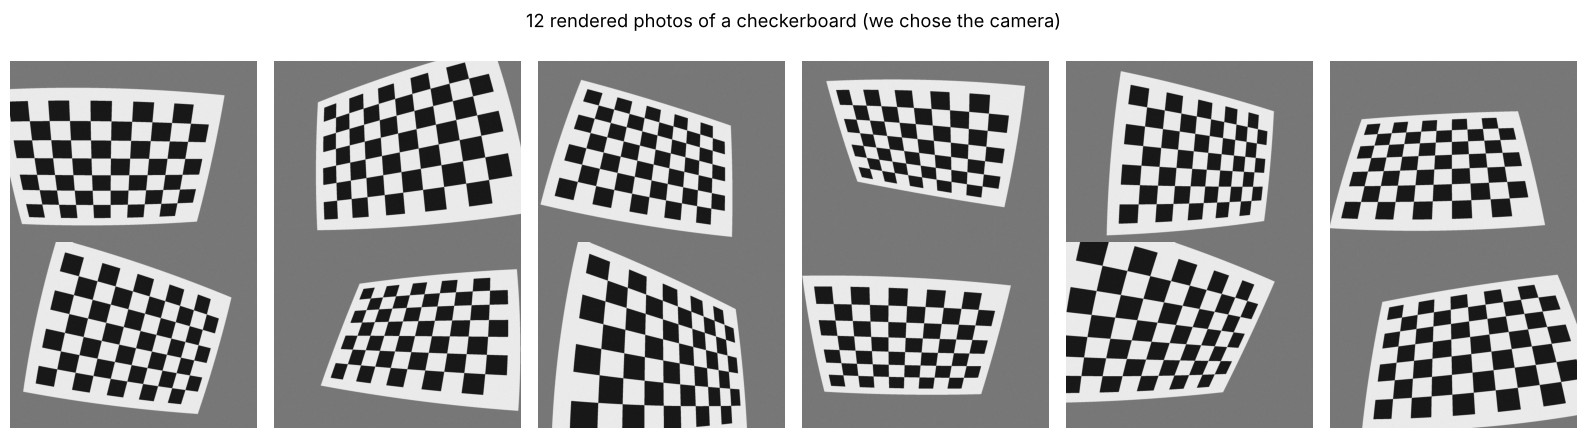

In [15]:
K_true = np.array([[600., 0, 330], [0, 600., 250], [0, 0, 1]])
k1_true, k2_true = -0.25, 0.08
IMG = (640, 480)
NX, NY = 9, 6                                       # inner corners (a 10 x 7 board of squares)

def undistort_norm(xd, k1, k2, iters=25):
    # invert the radial model by fixed-point iteration (normalised coordinates)
    x = xd.copy()
    for _ in range(iters):
        r2 = (x ** 2).sum(-1, keepdims=True)
        x = xd / (1 + k1 * r2 + k2 * r2 ** 2)
    return x

def render_board(K, k1, k2, R, t, size=IMG, ss=3, seed=0):
    # draw what the camera sees: for every pixel, follow its ray back to the board plane (Z = 0)
    w, h = size
    us, vs = np.meshgrid((np.arange(w * ss) + 0.5) / ss - 0.5, (np.arange(h * ss) + 0.5) / ss - 0.5)
    xd = np.stack([(us - K[0, 2]) / K[0, 0], (vs - K[1, 2]) / K[1, 1]], -1).reshape(-1, 2)
    x = undistort_norm(xd, k1, k2)
    Hn = np.column_stack([R[:, 0], R[:, 1], t])              # board (X, Y, 1) -> normalised image
    B = np.linalg.solve(Hn, np.column_stack([x, np.ones(len(x))]).T).T
    X, Y = B[:, 0] / B[:, 2], B[:, 1] / B[:, 2]
    inside = (X > -1.6) & (X < NX + 0.6) & (Y > -1.6) & (Y < NY + 0.6)     # board incl. a white margin
    squares = (X >= -1) & (X < NX) & (Y >= -1) & (Y < NY)
    dark = squares & ((np.floor(X) + np.floor(Y)) % 2 == 0)
    img = np.where(inside, np.where(dark, 25.0, 235.0), 120.0)             # grey background
    img = img.reshape(h * ss, w * ss)
    img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    img += np.random.default_rng(seed).normal(0, 2.0, img.shape)           # a little sensor noise
    return np.clip(img, 0, 255).astype(np.uint8)

def rot(rx, ry, rz):
    return cv2.Rodrigues(np.radians([rx, ry, rz]))[0]

rng = np.random.default_rng(1)
OBJ = np.zeros((NX * NY, 3), np.float32); OBJ[:, :2] = np.mgrid[0:NX, 0:NY].T.reshape(-1, 2)
synth, poses = [], []
while len(synth) < 12:
    R = rot(rng.uniform(-40, 40), rng.uniform(-40, 40), rng.uniform(-20, 20))
    centre = np.array([(NX - 1) / 2, (NY - 1) / 2, 0])
    t = np.array([rng.uniform(-1.5, 1.5), rng.uniform(-1, 1), rng.uniform(10, 14)]) - R @ centre
    # keep the pose only if every corner is well inside the photo
    xn = (R @ OBJ.T).T + t; xn = xn[:, :2] / xn[:, 2:]
    px = distort(xn, k1_true, k2_true) * 600 + (330, 250)
    if px.min() < 40 or px[:, 0].max() > 600 or px[:, 1].max() > 440: continue
    synth.append(render_board(K_true, k1_true, k2_true, R, t, seed=len(synth))); poses.append((R, t))

fig, ax = plt.subplots(2, 6, figsize=(16, 4.4))
for a, im in zip(ax.ravel(), synth): a.imshow(im, cmap="gray", vmin=0, vmax=255); a.axis("off")
plt.suptitle("12 rendered photos of a checkerboard (we chose the camera)", y=0.99)
plt.tight_layout(); plt.show()

In [16]:
CRIT = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-3)

def find_corners(gray, pattern=(NX, NY)):
    ok, c = cv2.findChessboardCorners(gray, pattern)
    if not ok: return None
    c = cv2.cornerSubPix(gray, c.reshape(-1, 1, 2).astype(np.float32), (7, 7), (-1, -1), CRIT)
    return c.reshape(-1, 2)

found = [find_corners(im) for im in synth]
print("corners found in", sum(c is not None for c in found), "of", len(synth), "rendered photos")
objs = [OBJ for c in found if c is not None]; imgs = [c for c in found if c is not None]
rms_s, K_s, d_s, rv_s, tv_s = cv2.calibrateCamera(objs, imgs, IMG, None, None)

print(f"\n{'':>6} {'true':>8} {'found':>9}")
for name, a, b in [("fx", K_true[0, 0], K_s[0, 0]), ("fy", K_true[1, 1], K_s[1, 1]),
                   ("cx", K_true[0, 2], K_s[0, 2]), ("cy", K_true[1, 2], K_s[1, 2]),
                   ("k1", k1_true, d_s.ravel()[0]), ("k2", k2_true, d_s.ravel()[1])]:
    print(f"{name:>6} {a:8.3f} {b:9.3f}")
print(f"\nreprojection error (RMS): {rms_s:.3f} px")

corners found in 12 of 12 rendered photos

           true     found
    fx  600.000   599.843
    fy  600.000   599.765
    cx  330.000   329.762
    cy  250.000   250.022
    k1   -0.250    -0.251
    k2    0.080     0.094

reprojection error (RMS): 0.087 px


Calibration recovers the camera we chose to within a pixel or so in $f$ and $c$, and closely in $k_1$
($k_2$ is harder to pin down; it trades off against $k_3$). The **reprojection error** is the check you always
look at: put the board's corners through the fitted camera and measure how far they land from the corners found
in the photo. A good calibration is well under 1 px.

## 8 · Calibrating a real camera

Now the 13 real photos. Same three steps; nobody knows the true answer, so the reprojection error is our check.

To see what the check catches, we add a 14th photo with a mistake in it: someone pressed the **zoom** button.
We fake that by cutting the middle 80% out of `left12` and enlarging it back to 640 × 480 (§3: a crop plus a
resize, so this photo has a different K from the others).

corners found in 14 of 14 photos


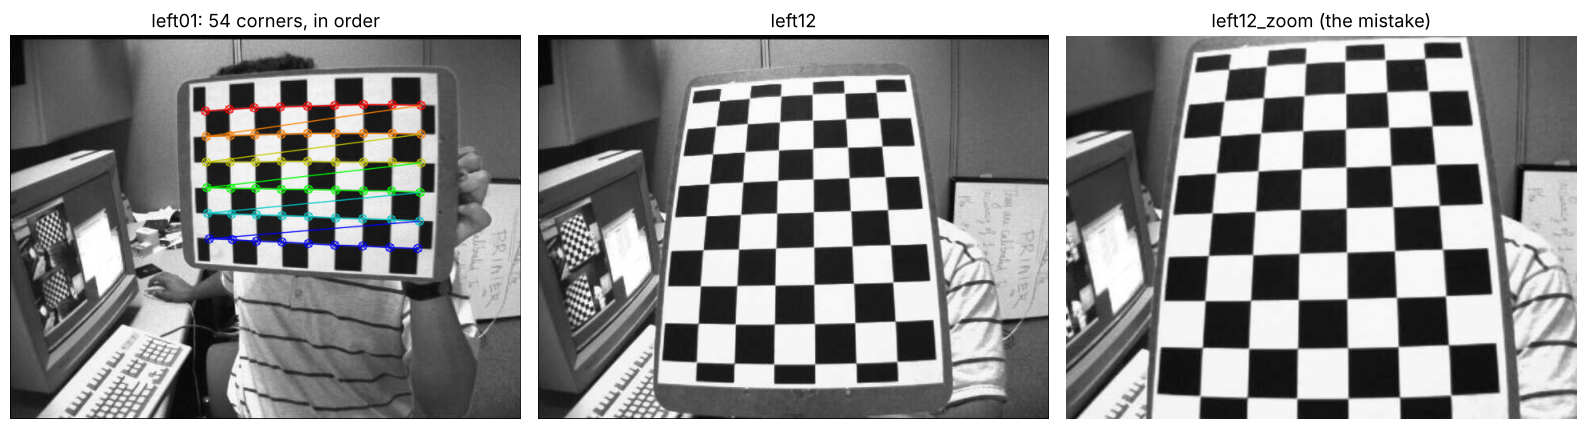

In [17]:
gray = [cv2.imread(f, cv2.IMREAD_GRAYSCALE) for f in FILES]
names = [os.path.basename(f)[:-4] for f in FILES]
z = gray[names.index("left12")][48:432, 64:576]                 # the middle 512 x 384 ...
gray.append(cv2.resize(z, (640, 480), interpolation=cv2.INTER_LINEAR))   # ... enlarged 1.25x
names.append("left12_zoom")

corners = [find_corners(g) for g in gray]
print("corners found in", sum(c is not None for c in corners), "of", len(gray), "photos")

show = cv2.cvtColor(gray[0], cv2.COLOR_GRAY2BGR)
cv2.drawChessboardCorners(show, (NX, NY), corners[0].reshape(-1, 1, 2), True)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].imshow(show[:, :, ::-1]); ax[0].set_title(f"{names[0]}: 54 corners, in order")
ax[1].imshow(gray[names.index("left12")], cmap="gray"); ax[1].set_title("left12")
ax[2].imshow(gray[-1], cmap="gray"); ax[2].set_title("left12_zoom (the mistake)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

all 14 photos: reprojection error (RMS) 0.471 px, fx = 540.9


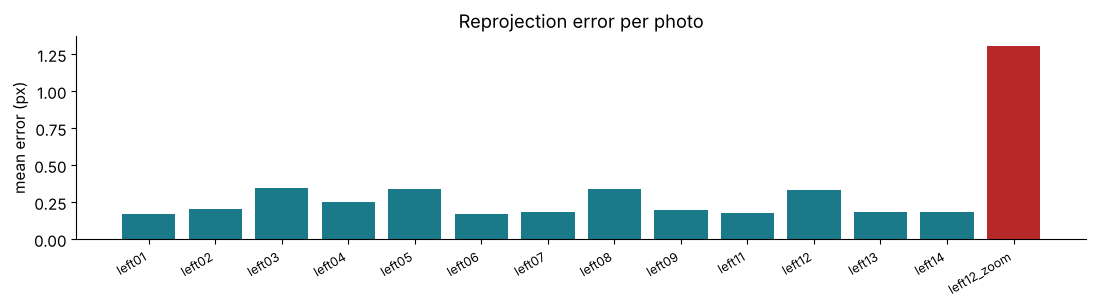

      left01: 0.17 px
      left02: 0.20 px
      left03: 0.35 px
      left04: 0.25 px
      left05: 0.34 px
      left06: 0.17 px
      left07: 0.18 px
      left08: 0.34 px
      left09: 0.20 px
      left11: 0.18 px
      left12: 0.33 px
      left13: 0.19 px
      left14: 0.19 px
 left12_zoom: 1.31 px


In [18]:
OBJ_REAL = OBJ.copy()          # one square = 1 unit (the real square size only scales t, not K)

def view_errors(K, d, rvecs, tvecs, cs):
    out = []
    for r, t, c in zip(rvecs, tvecs, cs):
        p, _ = cv2.projectPoints(OBJ_REAL, r, t, K, d)
        out.append(np.linalg.norm(p.reshape(-1, 2) - c, axis=1).mean())
    return np.array(out)

rms, K_all, d_all, rvecs, tvecs = cv2.calibrateCamera([OBJ_REAL] * len(corners), corners, (640, 480), None, None)
E = view_errors(K_all, d_all, rvecs, tvecs, corners)
print(f"all 14 photos: reprojection error (RMS) {rms:.3f} px, fx = {K_all[0,0]:.1f}")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(names, E, color=[RED if n == "left12_zoom" else TEAL for n in names])
ax.set_ylabel("mean error (px)"); ax.set_title("Reprojection error per photo")
plt.xticks(rotation=30, fontsize=9, ha="right"); plt.tight_layout(); plt.show()
for n, e in zip(names, E): print(f"{n:>12}: {e:.2f} px")

The 13 real photos sit between about 0.15 and 0.35 px; the zoomed one is about four times worse, and it drags the other photos up too,
because one K cannot fit both. That is the main use of the per-photo error: find the photos that don't fit
(zoomed, blurred, a bent board, a corner found in the wrong place), drop them, and calibrate again.

In [19]:
keep = [i for i in range(len(names)) if names[i] != "left12_zoom"]
rms2, K_real, d_real, rv2, tv2 = cv2.calibrateCamera([OBJ_REAL] * len(keep), [corners[i] for i in keep],
                                                     (640, 480), None, None)
print(f"without the zoomed photo: RMS {rms2:.3f} px (was {rms:.3f}), fx {K_real[0,0]:.1f} (was {K_all[0,0]:.1f})")
print("K =\n", K_real)
print("dist (k1, k2, p1, p2, k3) =", d_real.ravel())
print(f"image centre (320, 240) vs principal point ({K_real[0,2]:.1f}, {K_real[1,2]:.1f})")
fov = 2 * np.degrees(np.arctan(320 / K_real[0, 0]))
print(f"horizontal field of view: {fov:.1f} deg")

# How far does the lens move the corner pixel of the photo?
und = cv2.undistortPoints(np.array([[[0.0, 0.0]]]), K_real, d_real, P=K_real).reshape(2)
print(f"top-left pixel (0, 0) is where an ideal camera would put ({und[0]:.1f}, {und[1]:.1f}): "
      f"{np.linalg.norm(und):.0f} px away")
gray, corners, names = [gray[i] for i in keep], [corners[i] for i in keep], [names[i] for i in keep]

without the zoomed photo: RMS 0.183 px (was 0.471), fx 533.0 (was 540.9)
K =
 [[533.002   0.    342.309]
 [  0.    533.124 233.929]
 [  0.      0.      1.   ]]
dist (k1, k2, p1, p2, k3) = [-0.285  0.064  0.001 -0.     0.082]
image centre (320, 240) vs principal point (342.3, 233.9)
horizontal field of view: 62.0 deg
top-left pixel (0, 0) is where an ideal camera would put (-59.0, -40.9): 72 px away


**Undistorting.** With K and the distortion known, `cv2.undistort` remaps the photo so that straight lines are
straight again. To measure it, take the outermost row of corners and see how far the middle corners sit from the
straight line through its two ends ("bow").

In [20]:
def bows_of(pts):
    # for every row and column of corners: largest distance (px) from the straight line through its two ends
    g = pts.reshape(NY, NX, 2); lines = list(g) + list(g.transpose(1, 0, 2)); out = []
    for line in lines:
        a, b = line[0], line[-1]; n = np.array([-(b - a)[1], (b - a)[0]]); n /= np.linalg.norm(n)
        out.append(np.abs((line - a) @ n).max())
    return np.array(out), lines

def worst_bow(pts):
    b, lines = bows_of(pts); return b.max(), lines[b.argmax()]

bows = []
for i in range(len(names)):
    b0 = worst_bow(corners[i])[0]
    b1 = worst_bow(cv2.undistortPoints(corners[i].reshape(-1, 1, 2), K_real, d_real, P=K_real).reshape(-1, 2))[0]
    bows.append((names[i], b0, b1))
for n, b0, b1 in bows: print(f"{n}: bow {b0:.1f} px -> {b1:.2f} px after undistorting")
print(f"median: {np.median([b[1] for b in bows]):.1f} -> {np.median([b[2] for b in bows]):.2f} px")

left01: bow 2.8 px -> 0.34 px after undistorting
left02: bow 3.3 px -> 0.32 px after undistorting
left03: bow 4.8 px -> 0.50 px after undistorting
left04: bow 3.5 px -> 0.35 px after undistorting
left05: bow 4.9 px -> 0.53 px after undistorting
left06: bow 5.1 px -> 0.34 px after undistorting
left07: bow 2.6 px -> 0.35 px after undistorting
left08: bow 3.2 px -> 0.56 px after undistorting
left09: bow 2.9 px -> 0.46 px after undistorting
left11: bow 2.8 px -> 0.35 px after undistorting
left12: bow 4.0 px -> 0.41 px after undistorting
left13: bow 2.1 px -> 0.33 px after undistorting
left14: bow 3.4 px -> 0.31 px after undistorting
median: 3.3 -> 0.35 px


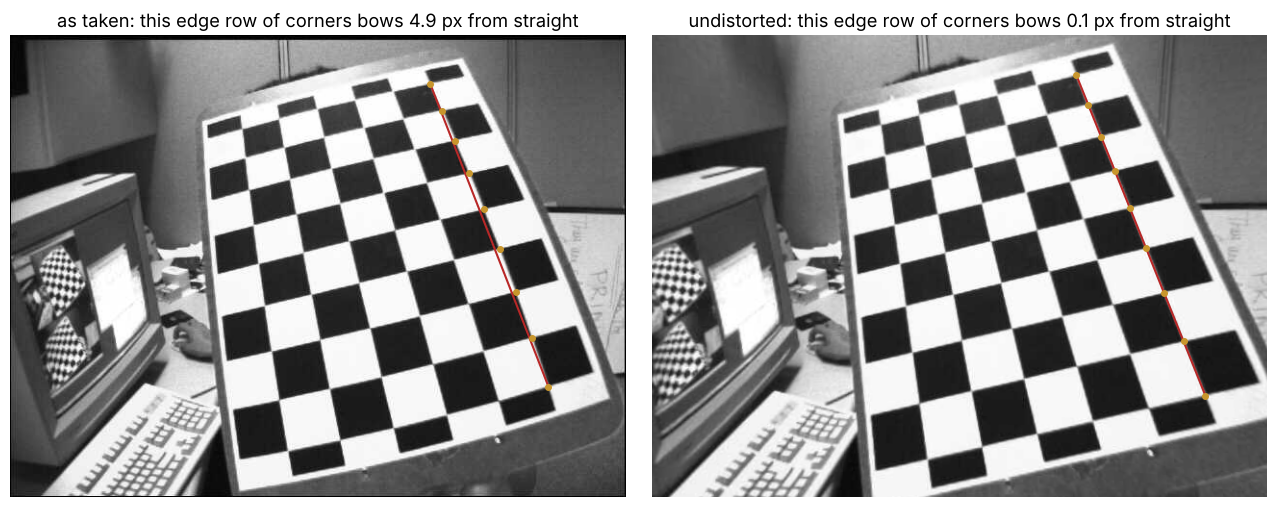

In [21]:
i = names.index("left05")
img = cv2.cvtColor(gray[i], cv2.COLOR_GRAY2RGB)
und_img = cv2.undistort(img, K_real, d_real)
c0 = corners[i]; c1 = cv2.undistortPoints(c0.reshape(-1, 1, 2), K_real, d_real, P=K_real).reshape(-1, 2)

k = bows_of(c0)[0].argmax()                     # the most bent row/column in the photo as taken
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, im, c, title in [(ax[0], img, c0, "as taken"), (ax[1], und_img, c1, "undistorted")]:
    a.imshow(im); b, lines = bows_of(c); line = lines[k]
    a.plot([line[0][0], line[-1][0]], [line[0][1], line[-1][1]], color=RED, lw=1.5)
    a.plot(line[:, 0], line[:, 1], "o", color=GOLD, ms=4)
    a.set_title(f"{title}: this edge row of corners bows {b[k]:.1f} px from straight"); a.axis("off")
plt.tight_layout(); plt.show()

## 9 · Pose: drawing a 3-D cube on the board

Calibration also returned the board's pose in every photo, and for a **new** photo with a known flat target
`cv2.solvePnP` finds R and t from the corners in one line. With K, distortion, R and t we can put any 3-D point
through the camera and draw it where it belongs. That is all augmented reality is (phone AR, the yellow
first-down line on TV football, virtual sets).

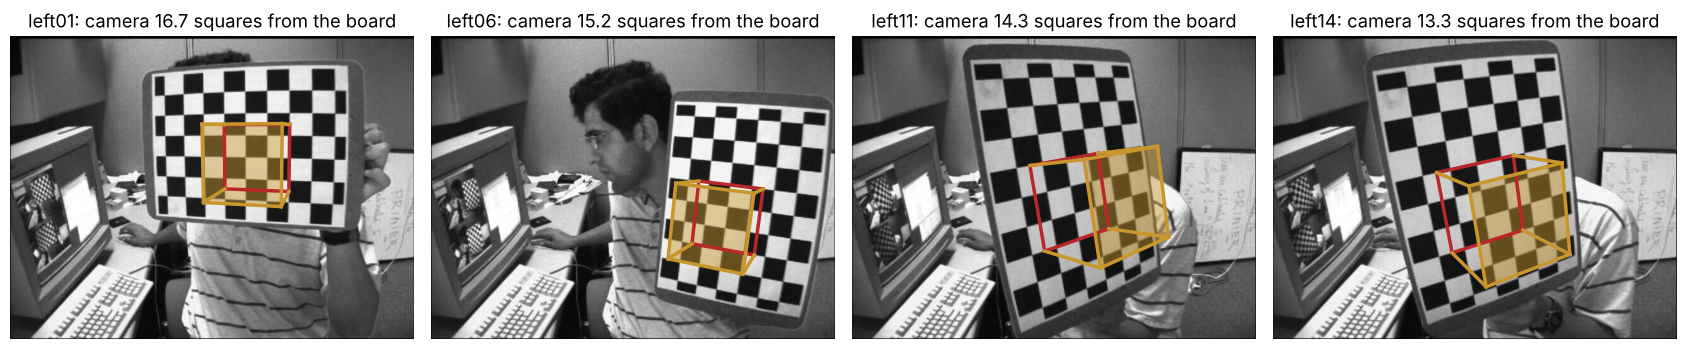

In [22]:
cube = np.float32([[0, 0, 0], [3, 0, 0], [3, 3, 0], [0, 3, 0],
                   [0, 0, -3], [3, 0, -3], [3, 3, -3], [0, 3, -3]]) + np.float32([3, 1.5, 0])
# z = -3 is towards the camera (the board's z axis points away from it)
CUBE_EDGES = [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),(0,4),(1,5),(2,6),(3,7)]

def draw_cube(i, ax):
    ok, r, t = cv2.solvePnP(OBJ_REAL, corners[i], K_real, d_real)
    p, _ = cv2.projectPoints(cube, r, t, K_real, d_real); p = p.reshape(-1, 2)
    ax.imshow(gray[i], cmap="gray")
    ax.fill(p[[4, 5, 6, 7], 0], p[[4, 5, 6, 7], 1], color=GOLD, alpha=0.45)
    for a, b in CUBE_EDGES:
        ax.plot([p[a, 0], p[b, 0]], [p[a, 1], p[b, 1]], color=GOLD if a >= 4 or b >= 4 else RED, lw=2.5)
    dist_sq = np.linalg.norm(t)
    ax.set_title(f"{names[i]}: camera {dist_sq:.1f} squares from the board"); ax.axis("off")

pick = [names.index(n) for n in ["left01", "left06", "left11", "left14"]]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, i in zip(ax, pick): draw_cube(i, a)
plt.tight_layout(); plt.show()

The cube's base sits on the board and its top comes out towards the camera, in every photo, from one K and one
pose per photo. If K or the distortion were wrong, the cube would slide around the board from photo to photo.

## 10 · The 1958 air camera

Survey cameras were calibrated in a lab, not with a checkerboard, and came with a certificate: the calibrated
focal length, the distortion curve, and the positions of the **fiducial marks**, small crosses in the corners of
every frame. Lines joining opposite fiducials cross at the principal point $(c_x, c_y)$: the camera marks its
own centre on every photo.

We don't have the certificate for these frames. The usual camera of the period took 9 × 9 inch (229 mm)
photos with a 6-inch (152 mm) lens; we **assume** that here.

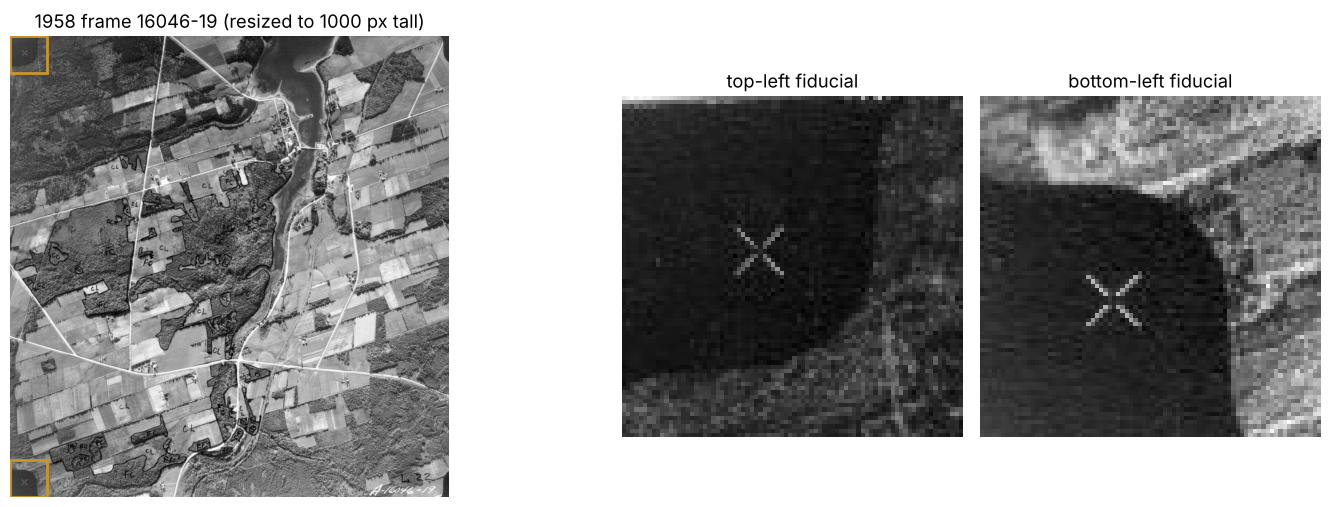

frame 953 x 1000 px: the right-hand edge (and its fiducials) was cut off when it was scanned


In [23]:
h, w = frame58.shape
fig, ax = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw={"width_ratios": [2.2, 1, 1]})
ax[0].imshow(frame58, cmap="gray"); ax[0].set_title("1958 frame 16046-19 (resized to 1000 px tall)")
for (x0, y0) in [(0, 0), (0, h - 80)]:
    ax[0].add_patch(plt.Rectangle((x0, y0), 80, 80, fill=False, ec=GOLD, lw=2))
ax[0].axis("off")
ax[1].imshow(frame58[:80, :80], cmap="gray"); ax[1].set_title("top-left fiducial")
ax[2].imshow(frame58[h - 80:, :80], cmap="gray"); ax[2].set_title("bottom-left fiducial")
for a in ax[1:]: a.axis("off")
plt.tight_layout(); plt.show()
print(f"frame {w} x {h} px: the right-hand edge (and its fiducials) was cut off when it was scanned")

In [24]:
full_h = 3000                                   # full-resolution scan height (px)
pitch = 229 / full_h                            # mm of film per scan pixel, if the frame is 229 mm tall
f_px = 152 / pitch                              # 6-inch lens, in scan pixels
gsd = 1.2                                       # m per scan pixel (measured against the maps, coastal build)
print(f"scan pixel = {pitch:.3f} mm of film -> f = 152 / {pitch:.3f} = {f_px:.0f} px")
print(f"ground pixel {gsd} m -> flying height H = GSD x f = {gsd * f_px:.0f} m")
print(f"photo scale 1 : {gsd * 1000 / pitch:,.0f}  (1 mm of film = {gsd / pitch:.1f} m of ground)")

scan pixel = 0.076 mm of film -> f = 152 / 0.076 = 1991 px
ground pixel 1.2 m -> flying height H = GSD x f = 2390 m
photo scale 1 : 15,721  (1 mm of film = 15.7 m of ground)


So with the usual lens the plane was about 2.4 km up and the photos are about 1 : 15,700. Two warnings for
projects: these numbers rest on the assumed lens, and the scan is cropped, so the middle of the scan is **not**
the principal point (crop moves $c_x$, §3). A homography fitted to matched points (L8) does not need either
number, which is one reason the course has used it for the 1958 photos.

## 11 · Try at home: calibrate your phone

1. **Make a board.** Run the cell below, then print `checkerboard_9x6.png` (or show it full-screen on a laptop;
   a screen is perfectly flat). Measure one square with a ruler.
2. **Take 15 photos** with your phone's 1× camera: fill most of the frame, tilt the board up to about 45° in
   different directions, and include the corners of the photo. Don't zoom.
3. **Calibrate.** Upload them to Colab, set `FILES` to your photos and `(640, 480)` to your photo size, and re-run
   §8. Is your RMS error under 1 px? Which photo is worst, and why?
4. **Check K.** Your phone's EXIF data gives the focal length in mm (and a "35 mm equivalent"). Does
   $f_\text{px} \approx f_\text{35mm} \times W / 36$ agree with your calibrated $f_x$?
5. **Try the 0.5× lens.** How much bigger is $k_1$? (Many phones correct distortion before saving the photo; if
   $k_1$ is near zero, yours does.)
6. **Projects.** Does your project need K at all? (Ground pixel size: yes. Matching two orthophotos: no.
   Flattening a Sharpe oblique: you need H, which you can fit from matches without knowing K.)

In [25]:
sq = 100                                           # pixels per square in the PNG
board = np.full(((NY + 1) * sq + 2 * sq, (NX + 1) * sq + 2 * sq), 255, np.uint8)
for r in range(NY + 1):
    for c in range(NX + 1):
        if (r + c) % 2 == 0:
            board[sq + r * sq: sq + (r + 1) * sq, sq + c * sq: sq + (c + 1) * sq] = 0
cv2.imwrite("checkerboard_9x6.png", board)
print("wrote checkerboard_9x6.png:", board.shape[::-1], "px, 10 x 7 squares = 9 x 6 inner corners")

wrote checkerboard_9x6.png: (1200, 900) px, 10 x 7 squares = 9 x 6 inner corners
